In [1]:
from gwosc import datasets
from matplotlib import mlab
from gwosc.datasets import find_datasets
from gwosc.datasets import event_gps
from scipy.interpolate import interp1d
from scipy.signal import butter, filtfilt
from gwpy.timeseries import TimeSeries
import numpy as np
import matplotlib.pyplot as plt
import os
import scipy
import scipy.signal
import scipy.interpolate

/home/gopal/miniconda3/envs/gwenv/lib/python3.10/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(True)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


In [2]:
tevent = event_gps('GW150914')
print(tevent)

duration = 104  # seconds
# Put GW150914 approximately at the center of the 104-second test window
start_time = tevent - 150
end_time   = tevent - 46

print("Start:", start_time)
print("End:", end_time)
print("Duration:", end_time - start_time, "seconds")

1126259462.4
Start: 1126259312.4
End: 1126259416.4
Duration: 104.0 seconds


In [3]:
segment = (int(tevent) - 150, int(tevent) -  46)
H1_data = TimeSeries.fetch_open_data('H1', *segment, verbose=True, cache=True)
L1_data = TimeSeries.fetch_open_data('L1', *segment, verbose=True, cache=True)

Fetched 1 URLs from gwosc.org for [1126259312 .. 1126259416))
Reading data... [Done]
Fetched 1 URLs from gwosc.org for [1126259312 .. 1126259416))
Reading data... [Done]


In [4]:
# GPS time arrays
time_H1_gps = np.asarray(H1_data.times.value).copy()
time_L1_gps = np.asarray(L1_data.times.value).copy()

# strain arrays
strain_H1 = np.asarray(H1_data.value).copy()
strain_L1 = np.asarray(L1_data.value).copy()

# Sampling information
fs = float(H1_data.sample_rate.value)
dt = 1.0 / fs

# GW150914 event GPS time
tevent = float(event_gps("GW150914"))

# Time relative to the event
time_relative = time_H1_gps - tevent

print("fs =", fs)
print("dt =", dt)
print("Time range relative to event:", time_relative[0], "to", time_relative[-1], "s")

fs = 4096.0
dt = 0.000244140625
Time range relative to event: -150.40000009536743 to -46.40024423599243 s


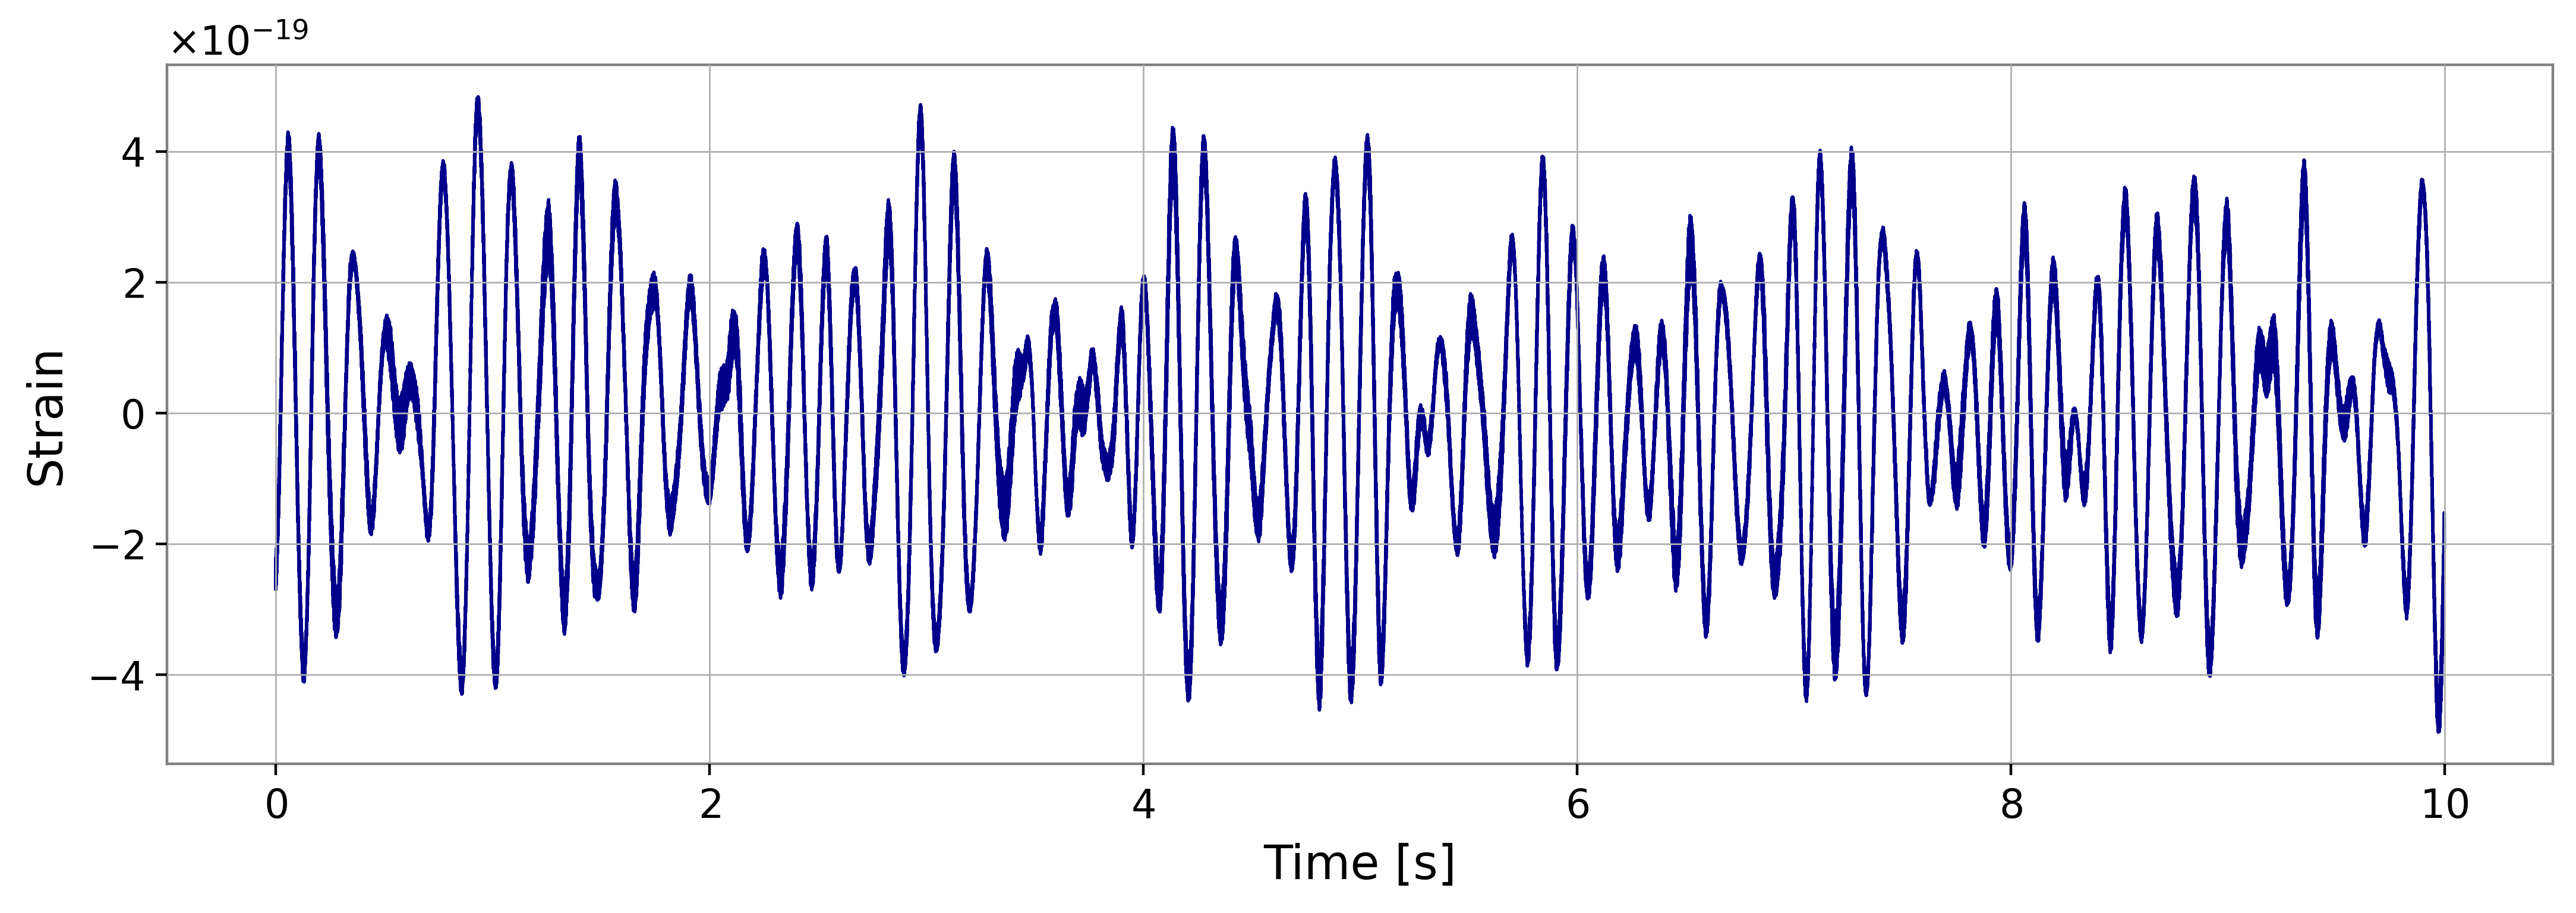

In [5]:
# Plot 1 second of RAW H1 detector data

plot_duration = 10.0
nplot = int(plot_duration * fs)

# Time axis
time = np.arange(nplot) / fs

plt.figure(figsize=(11, 4), dpi=400)

plt.plot(
    time,
    strain_H1[:nplot],
    color="darkblue",
    linewidth=1.0
)

plt.xlabel("Time [s]")
plt.ylabel("Strain")

plt.savefig("real_detector_noise.png", dpi = 400)
plt.tight_layout()
plt.show()

In [6]:
NFFT = int(1 * fs)
Pxx_H1, freqs_H1 = mlab.psd(strain_H1, Fs=fs, NFFT=NFFT)
Pxx_L1, freqs_L1 = mlab.psd(strain_L1, Fs=fs, NFFT=NFFT)
psd_H1 = interp1d(freqs_H1, Pxx_H1)
psd_L1 = interp1d(freqs_L1, Pxx_L1)

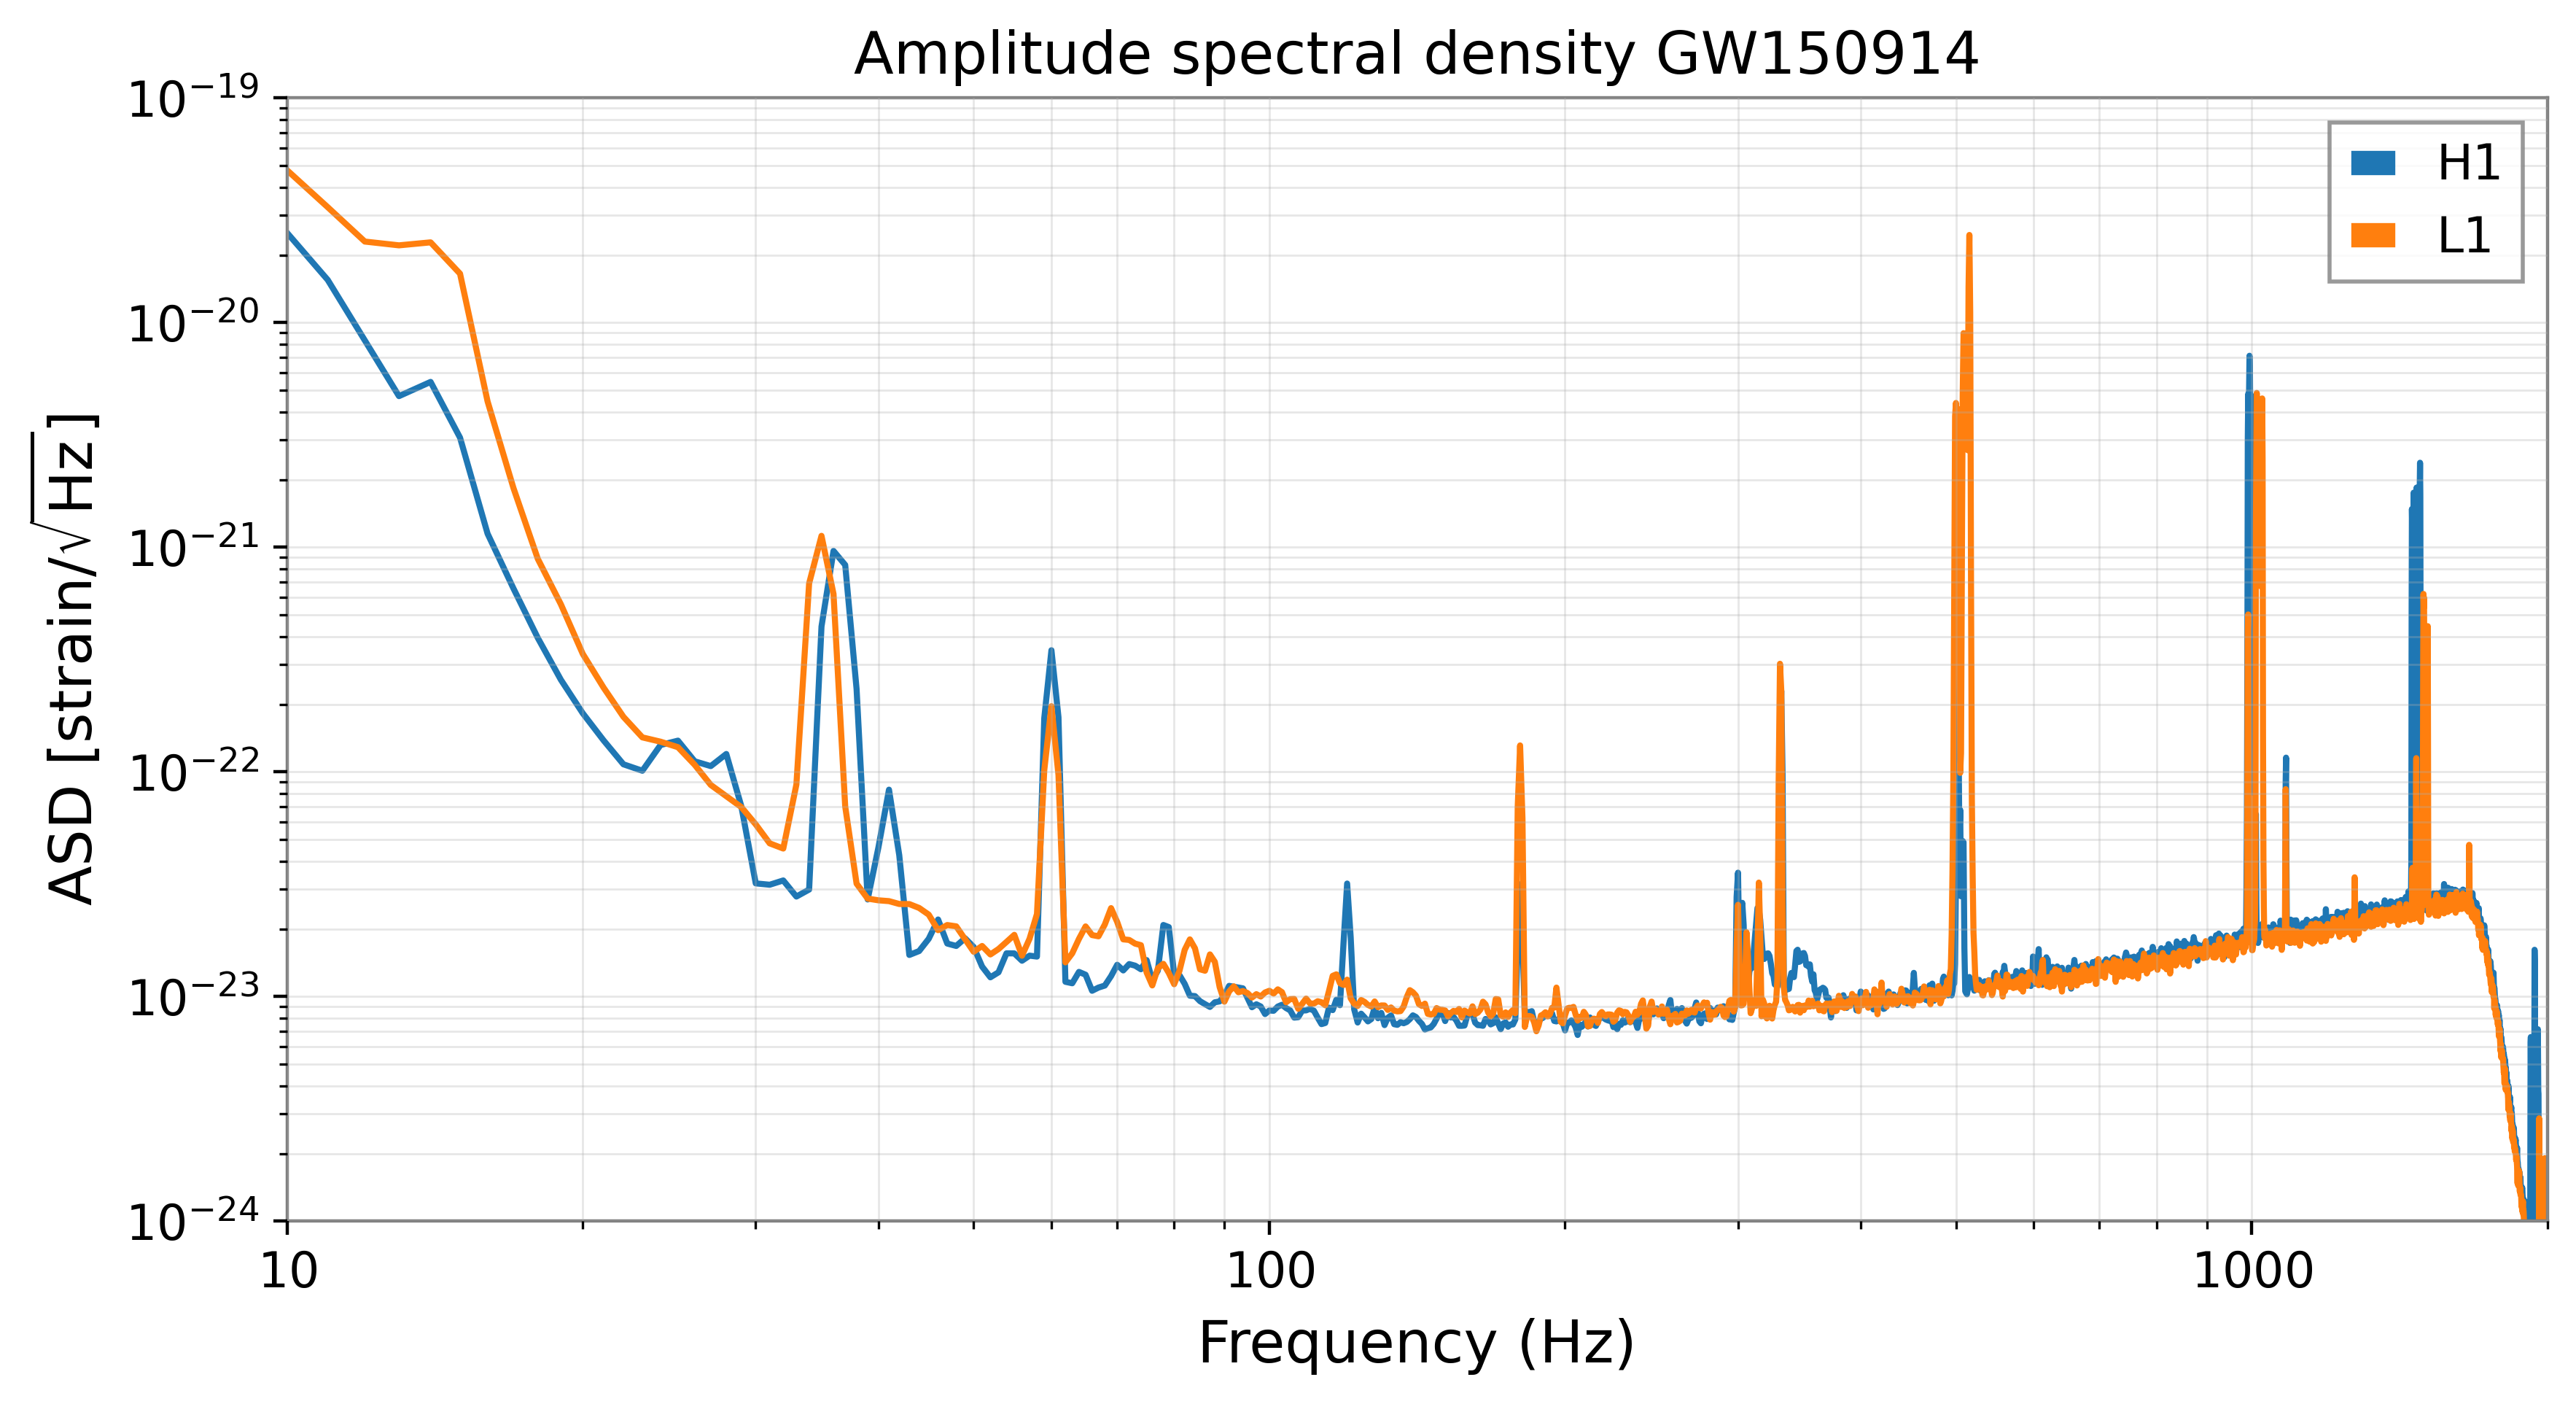

In [7]:
plt.figure(figsize=(10, 5), dpi = 400)
plt.loglog(freqs_H1, np.sqrt(Pxx_H1), label="H1")
plt.loglog(freqs_L1, np.sqrt(Pxx_L1), label="L1")
plt.xlim(10, 2000)
plt.ylim(1e-24, 1e-19)
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"ASD [strain/$\sqrt{\mathrm{Hz}}$]")
plt.title("Amplitude spectral density GW150914")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

In [8]:
def whiten(strain, interp_psd, dt):
    """
    Whitening convention used in the GWOSC GW150914 tutorial.
    """
    Nt = len(strain)
    freqs = np.fft.rfftfreq(Nt, dt)
    hf = np.fft.rfft(strain)
    white_hf = hf / np.sqrt(interp_psd(freqs) / dt / 2.0)
    white_ht = np.fft.irfft( white_hf, n=Nt)

    return white_ht

In [9]:
strain_H1_whiten = whiten(strain_H1, psd_H1, dt)
strain_L1_whiten = whiten(strain_L1, psd_L1, dt)

In [10]:
bb, ab = butter(
    4,
    [
        20.0 * 2.0 / fs,
        300.0 * 2.0 / fs
    ],
    btype="band"
)

strain_H1_whitenbp = filtfilt(bb, ab, strain_H1_whiten)
strain_L1_whitenbp = filtfilt(bb, ab,  strain_L1_whiten)

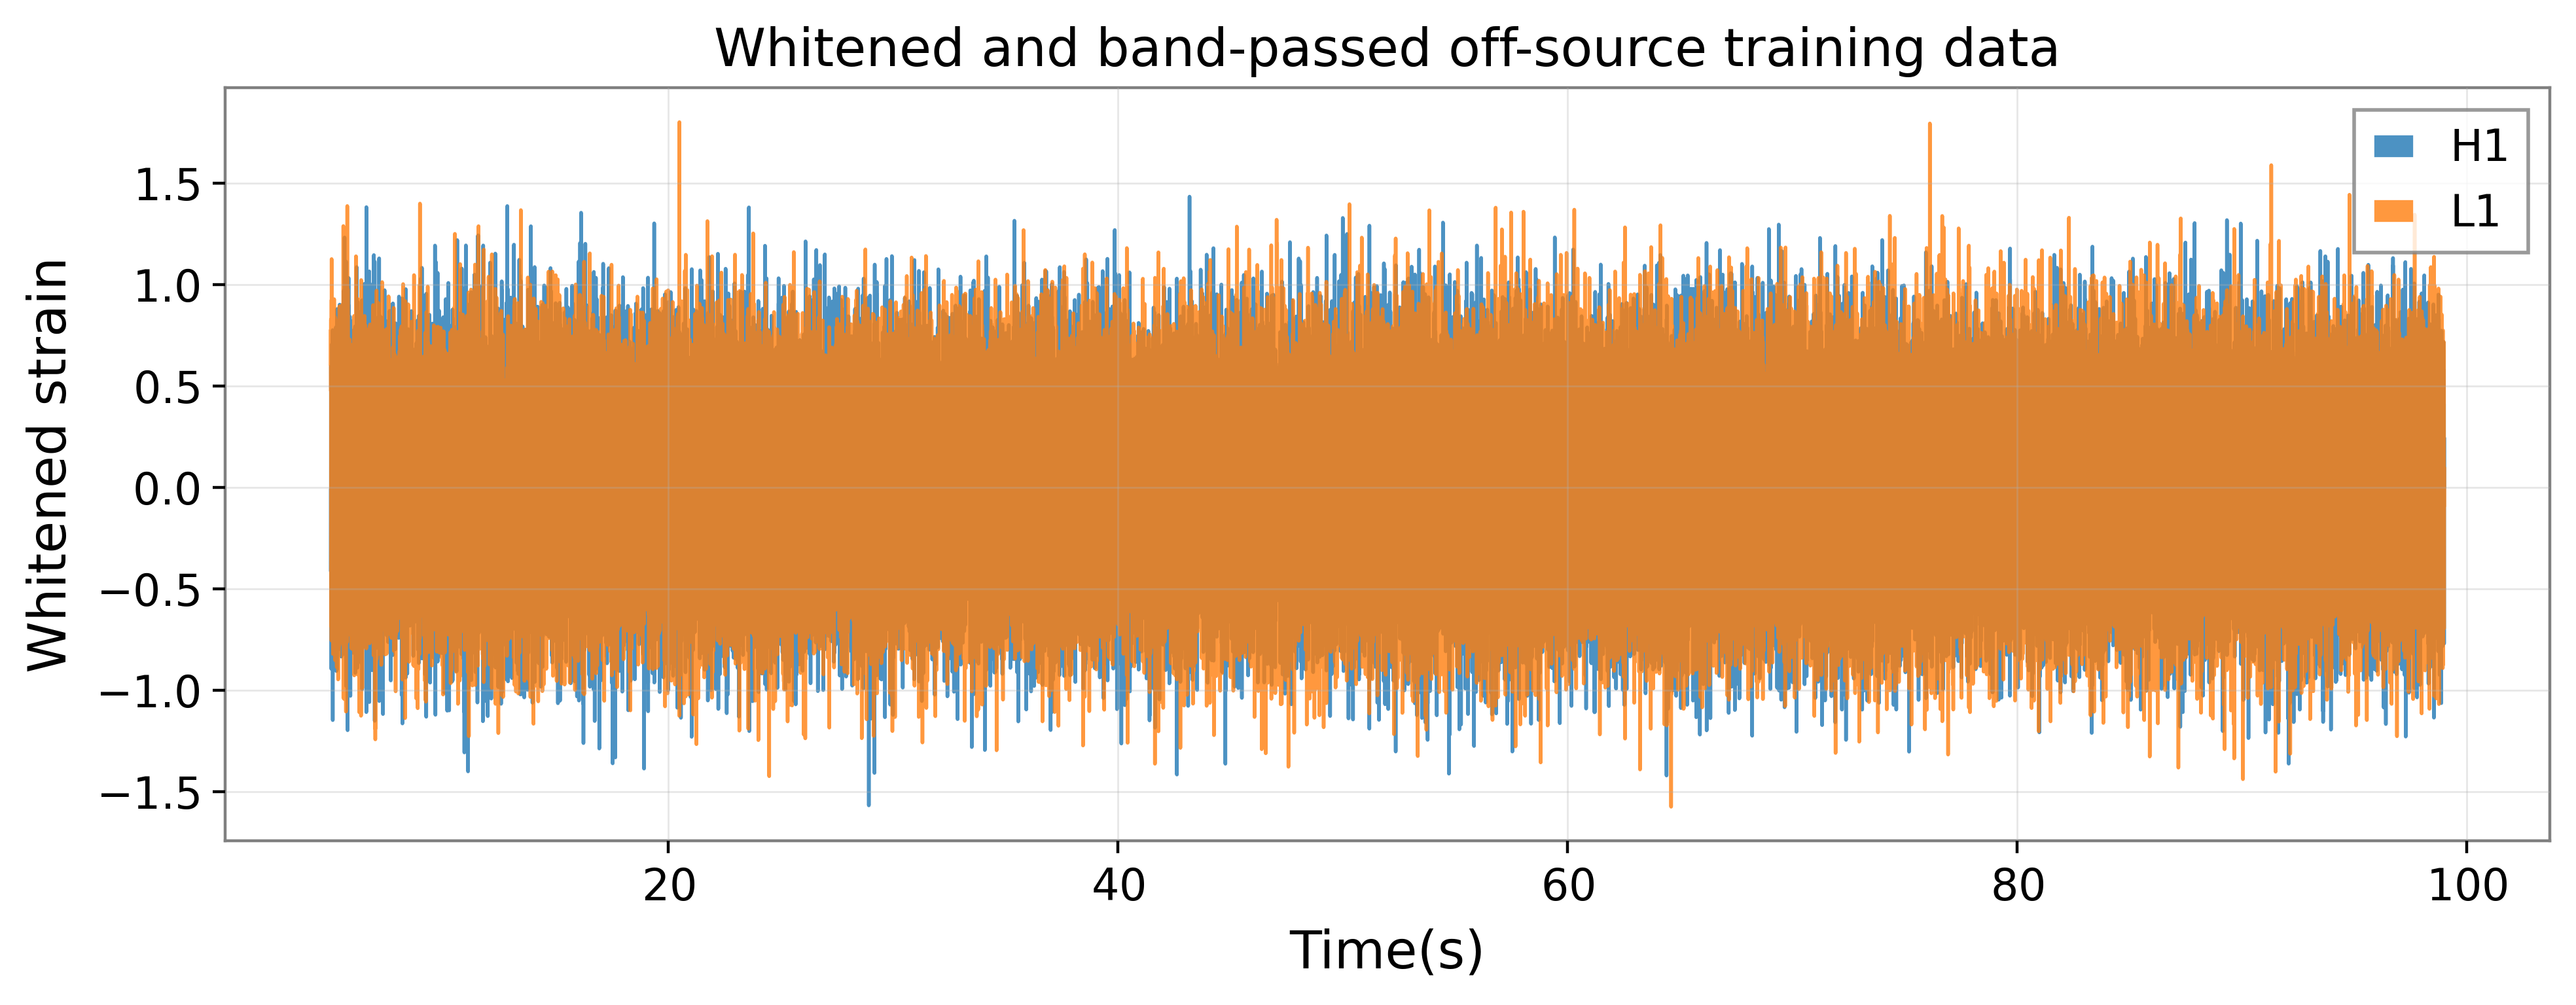

In [11]:
# Plot of the training segment

elapsed_time = time_H1_gps - time_H1_gps[0]
edge_seconds = 5.0
valid_mask = ((elapsed_time >= edge_seconds) & (elapsed_time <= elapsed_time[-1] - edge_seconds))

plt.figure(figsize=(10, 4), dpi=400)
plt.plot(elapsed_time[valid_mask], strain_H1_whitenbp[valid_mask], label="H1", linewidth= 1.0, alpha=0.8)
plt.plot(elapsed_time[valid_mask], strain_L1_whitenbp[valid_mask], label="L1", linewidth= 1.0, alpha=0.8)
plt.xlabel("Time(s)")
plt.ylabel("Whitened strain")
plt.title("Whitened and band-passed off-source training data")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

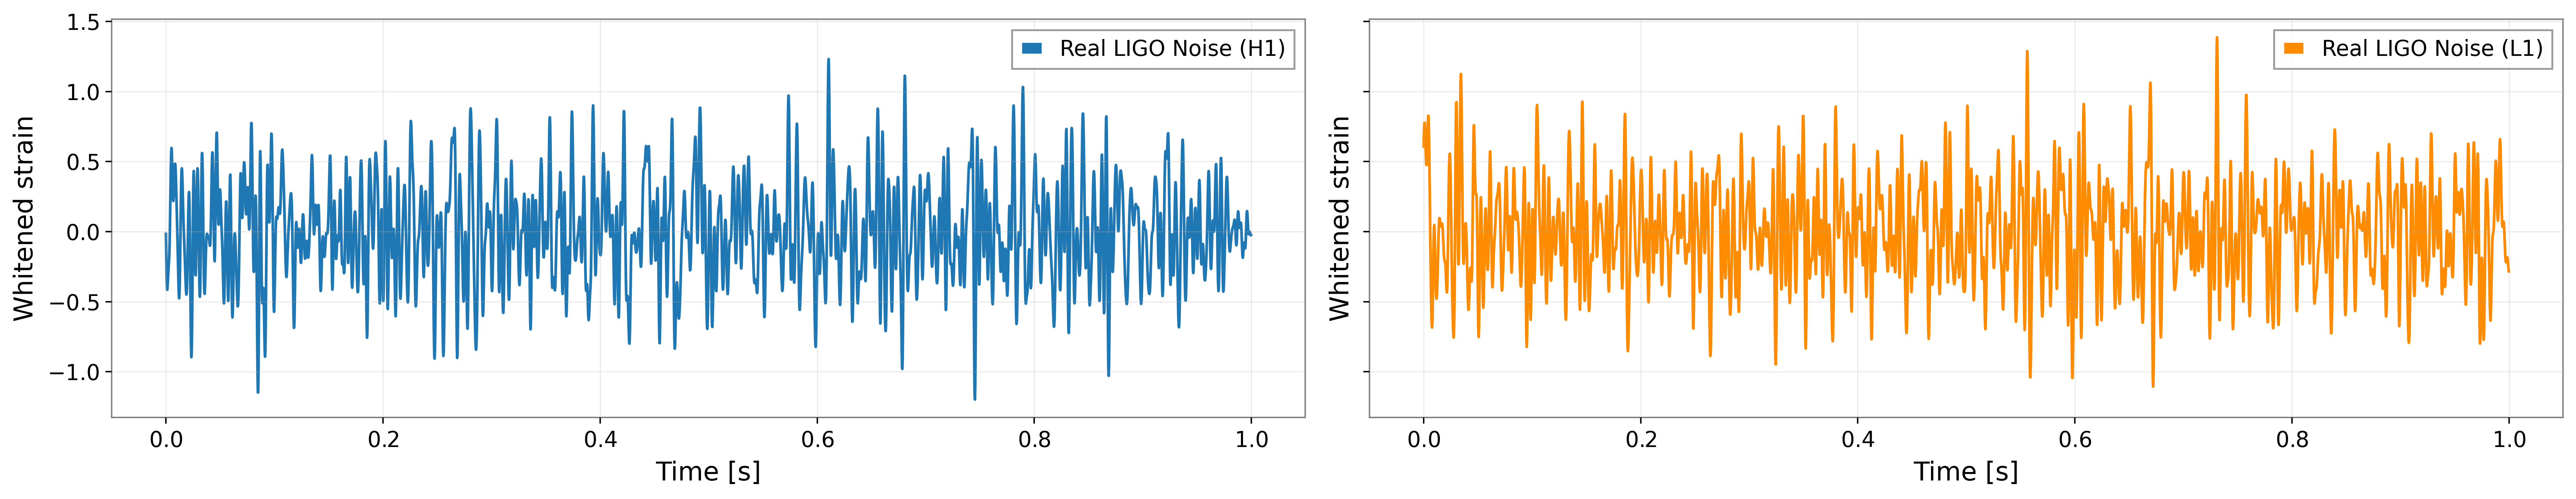

In [16]:
# Plot one representative second

N = int(fs)   # number of samples in 1 second
time_1s = np.arange(N) / fs

fig, axes = plt.subplots(1, 2, figsize=(20, 4), sharex=True, sharey=True, dpi=400)

# H1
axes[0].plot(
    time_1s,
    strain_H1_whitenbp[valid_mask][:N],
    linewidth=1.5,
    label="Real LIGO Noise (H1)"
)
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Whitened strain")
axes[0].grid(alpha=0.3)
axes[0].legend(loc='upper right')

# L1
axes[1].plot(
    time_1s,
    strain_L1_whitenbp[valid_mask][:N],
    linewidth=1.5,
    color="darkorange",
    label="Real LIGO Noise (L1)"
)
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Whitened strain")
axes[1].grid(alpha=0.3)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig("LIGONoise.png", dpi=400, bbox_inches='tight')
plt.show()

In [15]:
# Simple dot-product correlation between two arrays.
def cc(x, y):
    correlation = sum(a * b for a, b in zip(x, y))
    return correlation
    
# Cross-correlate two real detector data segments.
# data1: H1 segment
# data2: L1 segment
# times: time array for that segment

def cross_correlation_real_detector(data1, data2, times):
    data1 = data1 - np.mean(data1)
    data2 = data2 - np.mean(data2)

    correlations = []

    # Define lag range
    lags = np.arange(-len(times)//2, len(times)//2, 1)

    for lag in lags:
        data1_shifted = np.roll(data1, int(lag))

        correlation = cc(data1_shifted, data2)

        # Normalize by segment length
        correlation = correlation / len(times)

        correlations.append(correlation)

    correlations = np.array(correlations)

    return correlations, lags

In [14]:
# Remove first and last 2 seconds from 104 s data
# Then split the remaining 100 s into 100 one-second segments

num_files = 100

segment_duration = 1  # second
segment_samples = int(fs * segment_duration)  # 4096 samples

trim_duration = 2  # remove 2 seconds from both sides
trim_samples = int(fs * trim_duration)  # 8192 samples


# Keep only the middle 100 seconds
strain_H1_middle = strain_H1_whitenbp[trim_samples : trim_samples + num_files * segment_samples]
strain_L1_middle = strain_L1_whitenbp[trim_samples : trim_samples + num_files * segment_samples]

print("H1 middle-data shape:", strain_H1_middle.shape)
print("L1 middle-data shape:", strain_L1_middle.shape)

# Split middle 100 s into 100 one-second segments
h1_segments = []
l1_segments = []

for i in range(num_files):

    start_idx = i * segment_samples
    end_idx = start_idx + segment_samples

    h1_seg = strain_H1_middle[start_idx:end_idx]
    l1_seg = strain_L1_middle[start_idx:end_idx]

    h1_segments.append(h1_seg)
    l1_segments.append(l1_seg)


# Convert lists into NumPy arrays
h1_segments = np.array(h1_segments)
l1_segments = np.array(l1_segments)

print("H1 segments shape:", h1_segments.shape)
print("L1 segments shape:", l1_segments.shape)

H1 middle-data shape: (409600,)
L1 middle-data shape: (409600,)
H1 segments shape: (100, 4096)
L1 segments shape: (100, 4096)


In [15]:
# Time array for one segment
times = np.arange(segment_samples) / fs

print("Time array shape:", times.shape)
print("Start time:", times[0])
print("End time:", times[-1])

Time array shape: (4096,)
Start time: 0.0
End time: 0.999755859375


In [16]:
# Build 100 GW_real training files using noise-only H1 and L1 data

save_folder = "../TranAD_MGB/data/GW150914/train/"

os.makedirs(save_folder, exist_ok=True)

num_files = 100
segment_samples = 4096      
section_samples = 1024       # 1 second split into 4 parts
fs = int(fs)

# Store maximum absolute cross-correlation from each training file
maxccs = []

for i in range(num_files):

    # Take one 1-second noise-only H1 and L1 segment
    noise1 = h1_segments[i]
    noise2 = l1_segments[i]

    # Convert to NumPy arrays
    noise1 = np.asarray(noise1)
    noise2 = np.asarray(noise2)

    # Remove mean
    noise1 = noise1 - np.mean(noise1)
    noise2 = noise2 - np.mean(noise2)

    # Split each 1-second file into 4 sections
    noise1_sec1 = noise1[0:1024]
    noise1_sec2 = noise1[1024:2048]
    noise1_sec3 = noise1[2048:3072]
    noise1_sec4 = noise1[3072:4096]

    noise2_sec1 = noise2[0:1024]
    noise2_sec2 = noise2[1024:2048]
    noise2_sec3 = noise2[2048:3072]
    noise2_sec4 = noise2[3072:4096]

    # Time array for each 1024-sample section
    times_sec = np.arange(0, section_samples) / fs

    # Cross-correlation for each section
    ccnoise1, lags1 = cross_correlation_real_detector(noise1_sec1,noise2_sec1,times_sec)
    ccnoise2, lags2 = cross_correlation_real_detector(noise1_sec2,noise2_sec2,times_sec)
    ccnoise3, lags3 = cross_correlation_real_detector(noise1_sec3, noise2_sec3, times_sec)
    ccnoise4, lags4 = cross_correlation_real_detector(noise1_sec4, noise2_sec4, times_sec)

    # Combine the 4 cross-correlation sections
    # Each section has 1024 values, so final_sig has 4096 values
    final_sig = np.concatenate((ccnoise1, ccnoise2, ccnoise3, ccnoise4))

    # Store maximum absolute cross-correlation
    maxcc = np.max(np.abs(final_sig))
    maxccs.append(maxcc)

    # Save training file
    filename = str(i) + "_GW150914_train.txt"

    np.savetxt(os.path.join(save_folder, filename),final_sig)

    print("saved training file", i)

maxccs = np.array(maxccs)

print("Done.")
print("Number of training files:", num_files)
print("Maximum absolute cross-correlation:", np.max(maxccs))
print("Mean maximum cross-correlation:", np.mean(maxccs))

saved training file 0
saved training file 1
saved training file 2
saved training file 3
saved training file 4
saved training file 5
saved training file 6
saved training file 7
saved training file 8
saved training file 9
saved training file 10
saved training file 11
saved training file 12
saved training file 13
saved training file 14
saved training file 15
saved training file 16
saved training file 17
saved training file 18
saved training file 19
saved training file 20
saved training file 21
saved training file 22
saved training file 23
saved training file 24
saved training file 25
saved training file 26
saved training file 27
saved training file 28
saved training file 29
saved training file 30
saved training file 31
saved training file 32
saved training file 33
saved training file 34
saved training file 35
saved training file 36
saved training file 37
saved training file 38
saved training file 39
saved training file 40
saved training file 41
saved training file 42
saved training file 4

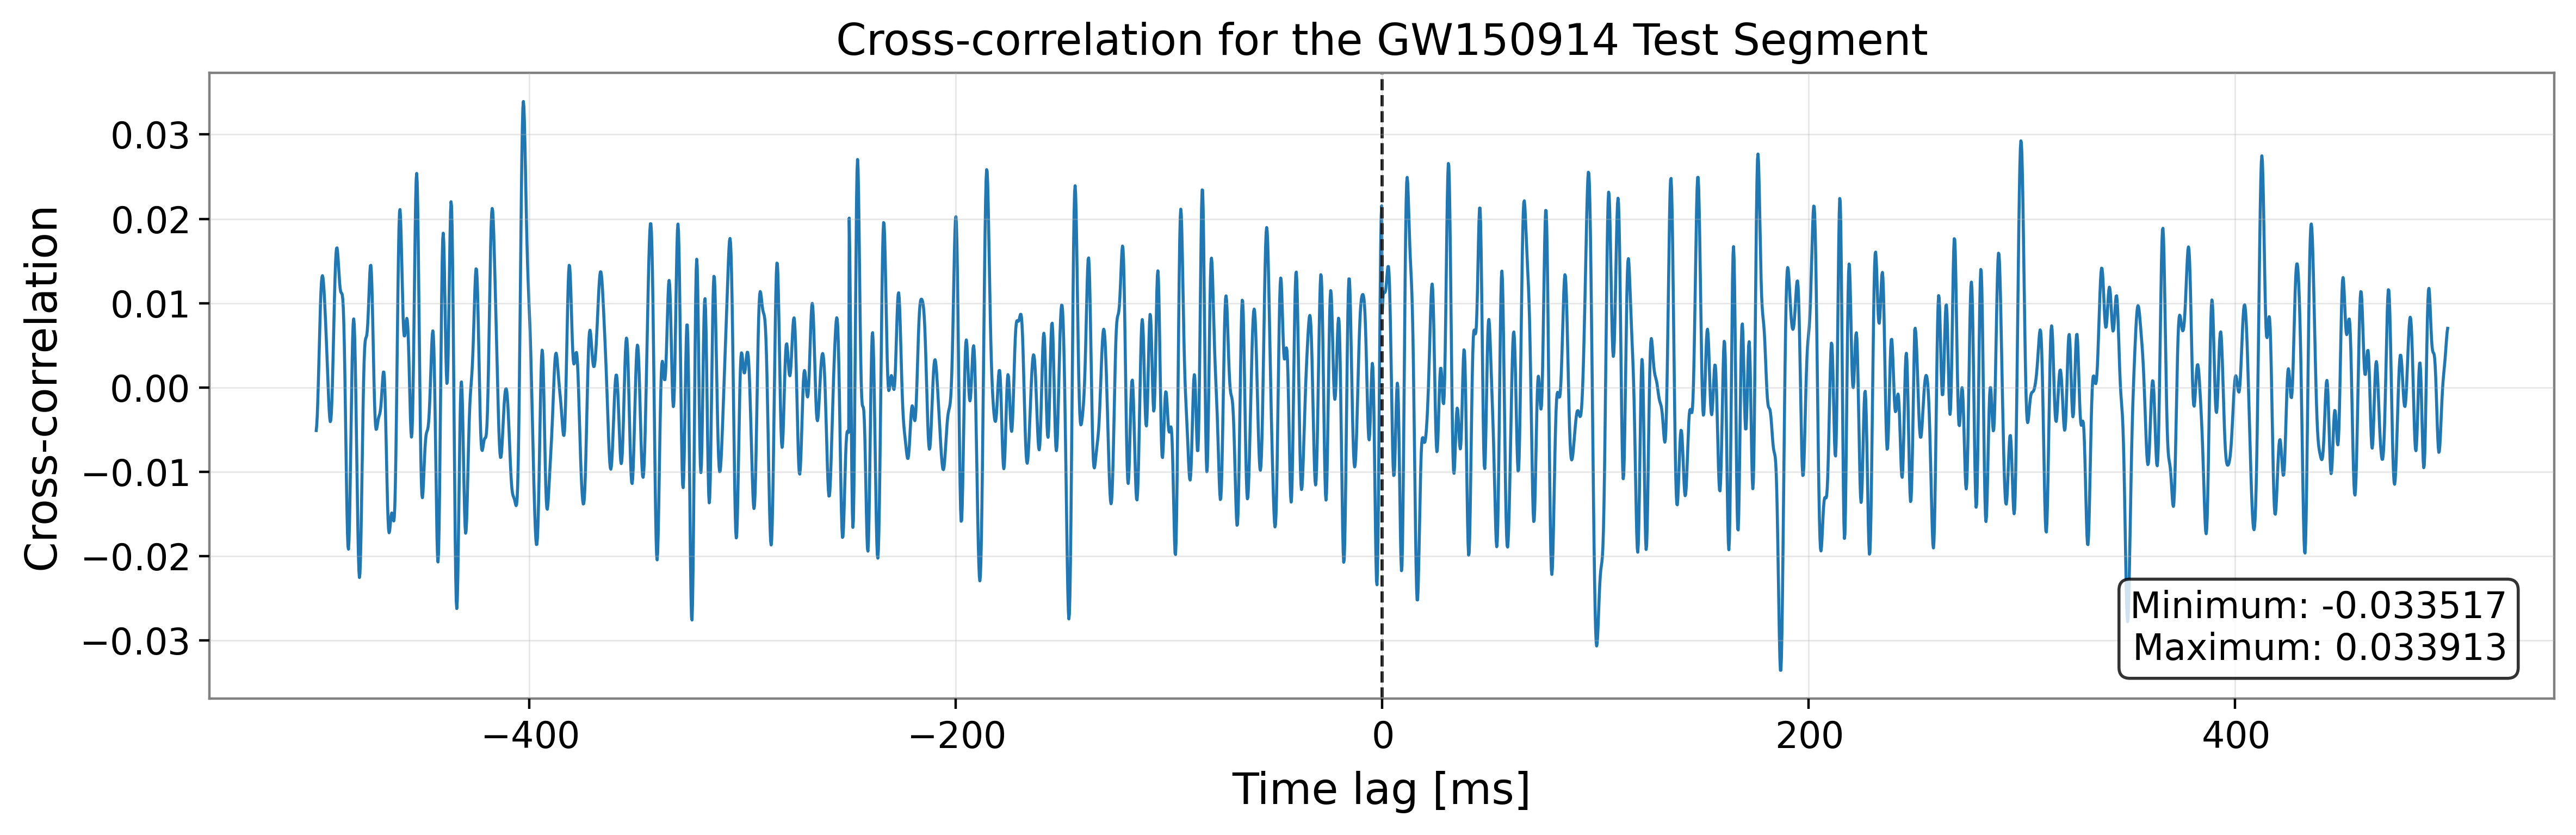

In [17]:
# plot
signal_file_index = 10

train_file = (f"../TranAD_MGB/data/GW150914/train/" f"{signal_file_index}_GW150914_train.txt")

sample = np.loadtxt(train_file)

fs = 4096 

# Same lag definition used by cross_correlation_real_detector()
lags_samples = np.arange(-len(sample) // 2, len(sample) // 2, 1)

# Convert samples into milliseconds
lags_ms = (lags_samples / fs) * 1000.0

# Minimum and maximum cross-correlation values
min_value = sample.min()
max_value = sample.max()

plt.figure(figsize=(12, 4), dpi=400)

plt.plot(lags_ms,sample,linewidth=1.0)
plt.axvline(0,color="black",linestyle="--",linewidth=1.0) # Zero lag
plt.xlabel("Time lag [ms]")
plt.ylabel("Cross-correlation")
plt.title("Cross-correlation for the GW150914 Test Segment")

# Display minimum and maximum values inside the plot
plt.text(0.98, 0.05, f"Minimum: {min_value:.6f}\n" f"Maximum: {max_value:.6f}", transform=plt.gca().transAxes, horizontalalignment="right",
         verticalalignment="bottom",bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()